# Per-time field embedding (representation learning)

Build one feature vector per timepoint by summarizing the **whole field** at that moment:
- **Spots**: density, NN distance, quality, morphology
- **Edges**: motion speed, cosine alignment with wave direction
- **Waves** (Roboflow): polygon area / centroid of largest wave

Then reduce dimensionality (PCA, UMAP, t-SNE) to visualize assay **phase trajectory**.

**Wave cutoff:** for `POSITION_T > 1250`, wave fields are set to **0** (waves absent after that time in this assay).

**Time convention:** same unreverse as `edge-features-3.ipynb` so `t=0` is chronological start.


## Is this feasible with correlated time-series data?

**Short answer: yes, but interpret it as dynamics, not i.i.d. samples.**

Each timepoint is **not independent** — neighboring times share tracking state, spatial structure, and wave history. That means:

| What still works | What to avoid |
|---|---|
| PCA/UMAP as **visual summary** of how the field evolves | Treating 4000 times as 4000 independent draws for p-values |
| Finding **phase transitions** (regime changes) | Random train/test splits across adjacent times |
| Correlating latent coords with known events (e.g. t=500) | Claiming latent axes are "causal" without controls |

**Mitigations if you go further:**
1. **Block holdout** — train on even times, validate on odd (or split by contiguous windows).
2. **Use differences** — embed Δfeatures (change from t−1) to reduce autocorrelation.
3. **Subsample time** — e.g. every 15 frames (one per assay minute).
4. **Smooth / detrend** — rolling z-score per feature before PCA.
5. **State-space models** — HMM or GP-LVM if you want explicit temporal structure.

For exploratory science (where is the assay on a low-D manifold?), correlated observations are **expected**, not a blocker.


In [1]:
import json
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial import cKDTree
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Repo root
current_dir = Path.cwd()
if current_dir.name == "analysis":
    repo_root = current_dir.parent
else:
    repo_root = current_dir
os.chdir(repo_root)
if str(repo_root / "roboflow" / "images") not in sys.path:
    sys.path.insert(0, str(repo_root / "roboflow" / "images"))

from wave_geometry import frame_index_from_name, largest_polygon_centroid, parse_predictions_blob

WAVE_CUTOFF_T = 1250  # waves absent after this POSITION_T
WAVE_RESULTS_DIR = repo_root / "roboflow" / "images" / "results" / "2026-05-16_232640"
SECONDS_PER_FRAME = 15

# Fixed wave direction (same as edge-features-3)
wx, wy = -0.875, -0.485
w_norm = np.hypot(wx, wy)
wave_x_unit, wave_y_unit = wx / w_norm, wy / w_norm

sns.set_theme(style="whitegrid")
print("Working directory:", repo_root)


Working directory: /Users/svngo/Documents/GitHub/Dicty-Cell-Aggregation-Analysis


In [2]:
# Load TrackMate exports (skip descriptive header rows)
edges = pd.read_csv("results/trial_5/highdensity_edges.csv", header=0, skiprows=[1, 2, 3], low_memory=False)
spots = pd.read_csv("results/trial_5/highdensity_spots.csv", header=0, skiprows=[1, 2, 3], low_memory=False)
tracks = pd.read_csv("results/trial_5/highdensity_tracks.csv", header=0, skiprows=[1, 2, 3], low_memory=False)

num_cols = {
    "edges": ["EDGE_TIME", "SPOT_SOURCE_ID", "SPOT_TARGET_ID", "SPEED", "DISPLACEMENT"],
    "spots": ["ID", "POSITION_X", "POSITION_Y", "POSITION_T", "QUALITY", "AREA", "PERIMETER"],
    "tracks": ["TRACK_ID", "TRACK_START", "TRACK_STOP", "TRACK_MEAN_QUALITY"],
}
for c in num_cols["edges"]:
    edges[c] = pd.to_numeric(edges[c], errors="coerce")
for c in num_cols["spots"]:
    spots[c] = pd.to_numeric(spots[c], errors="coerce")
for c in num_cols["tracks"]:
    tracks[c] = pd.to_numeric(tracks[c], errors="coerce")

# Unreverse time + edge direction (edge-features-3 convention)
tmax = spots["POSITION_T"].max()
spots["POSITION_T"] = tmax - spots["POSITION_T"]

etmax = edges["EDGE_TIME"].max()
edges["EDGE_TIME"] = etmax - edges["EDGE_TIME"]
edges[["SPOT_SOURCE_ID", "SPOT_TARGET_ID"]] = edges[["SPOT_TARGET_ID", "SPOT_SOURCE_ID"]].to_numpy()

ttmax = tracks["TRACK_STOP"].max()
tracks["TRACK_START"], tracks["TRACK_STOP"] = (
    ttmax - tracks["TRACK_STOP"],
    ttmax - tracks["TRACK_START"],
)

spots = spots.sort_values(["TRACK_ID", "POSITION_T"]).reset_index(drop=True)
edges = edges.sort_values(["TRACK_ID", "EDGE_TIME"]).reset_index(drop=True)

print("spots", spots.shape, "edges", edges.shape)
print("POSITION_T range:", spots["POSITION_T"].min(), "->", spots["POSITION_T"].max())


spots (557431, 31) edges (551198, 13)
POSITION_T range: 0.0 -> 3999.0


In [3]:
# Merge edges with spot positions and compute edge velocity + cosine
spot_cols = ["ID", "POSITION_X", "POSITION_Y", "POSITION_T"]
merged = edges.merge(spots[spot_cols], left_on="SPOT_SOURCE_ID", right_on="ID", how="inner")
merged = merged.rename(columns={
    "POSITION_X": "POSITION_X_source",
    "POSITION_Y": "POSITION_Y_source",
    "POSITION_T": "POSITION_T_source",
}).drop(columns=["ID"])

merged = merged.merge(spots[spot_cols], left_on="SPOT_TARGET_ID", right_on="ID", how="inner")
merged = merged.rename(columns={
    "POSITION_X": "POSITION_X_target",
    "POSITION_Y": "POSITION_Y_target",
    "POSITION_T": "POSITION_T_target",
}).drop(columns=["ID"])

delta_T = merged["POSITION_T_target"] - merged["POSITION_T_source"]
merged["V_x"] = (merged["POSITION_X_target"] - merged["POSITION_X_source"]) / delta_T
merged["V_y"] = (merged["POSITION_Y_target"] - merged["POSITION_Y_source"]) / delta_T

pixel_to_micron = 0.325
merged["V_x"] = merged["V_x"] * pixel_to_micron / SECONDS_PER_FRAME
merged["V_y"] = merged["V_y"] * pixel_to_micron / SECONDS_PER_FRAME * -1

V_mag = np.hypot(merged["V_x"], merged["V_y"])
merged["cosine"] = np.where(
    V_mag > 0,
    (merged["V_x"] / V_mag) * wave_x_unit + (merged["V_y"] / V_mag) * wave_y_unit,
    np.nan,
)
merged["is_stationary"] = V_mag == 0

print("merged rows:", len(merged))
print("finite cosine:", merged["cosine"].notna().sum())


merged rows: 551198
finite cosine: 365765


In [4]:
# --- Per-time SPOT features ---

def mean_nn_distance(xy: np.ndarray) -> float:
    if len(xy) < 2:
        return np.nan
    tree = cKDTree(xy)
    d, _ = tree.query(xy, k=2)
    return float(d[:, 1].mean())

spot_rows = []
for t, grp in spots.groupby("POSITION_T"):
    xy = grp[["POSITION_X", "POSITION_Y"]].to_numpy(dtype=float)
    spot_rows.append({
        "POSITION_T": t,
        "n_spots": len(grp),
        "mean_quality": grp["QUALITY"].mean(),
        "median_quality": grp["QUALITY"].median(),
        "mean_area": grp["AREA"].mean(),
        "mean_perimeter": grp["PERIMETER"].mean(),
        "mean_nn_dist": mean_nn_distance(xy),
    })

spot_feats = pd.DataFrame(spot_rows)
print("spot timepoints:", len(spot_feats))
spot_feats.head()


spot timepoints: 4000


,POSITION_T,n_spots,mean_quality,median_quality,mean_area,mean_perimeter,mean_nn_dist
0,0.0,538,83.834572,58.5,83.468401,37.650251,14.705973
1,1.0,544,83.553309,59.0,83.065257,37.616742,14.645106
2,2.0,546,83.402930,59.0,82.905678,37.529810,14.614943
3,3.0,542,84.001845,59.0,83.561808,37.658570,14.640094
4,4.0,542,83.870849,59.0,83.374539,37.634431,14.625907


In [5]:
# --- Per-time EDGE features ---
edge_feats = (
    merged.groupby("EDGE_TIME")
    .agg(
        n_edges=("cosine", "size"),
        mean_speed=("SPEED", "mean"),
        std_speed=("SPEED", "std"),
        mean_cosine=("cosine", "mean"),
        std_cosine=("cosine", "std"),
        frac_cos_neg1=("cosine", lambda s: np.isclose(s, -1.0).mean()),
        frac_cos_pos1=("cosine", lambda s: np.isclose(s, 1.0).mean()),
        frac_stationary=("is_stationary", "mean"),
    )
    .reset_index()
    .rename(columns={"EDGE_TIME": "POSITION_T"})
)
print("edge timepoints:", len(edge_feats))
edge_feats.head()


edge timepoints: 5403


,POSITION_T,n_edges,mean_speed,std_speed,mean_cosine,std_cosine,frac_cos_neg1,frac_cos_pos1,frac_stationary
0,0.0,535,0.139542,0.328676,-0.067575,0.727227,0.003738,0.005607,0.454206
1,0.5,1,0.235441,NaN,-0.496834,NaN,0.000000,0.000000,0.000000
2,1.0,537,0.148476,0.308358,-0.022595,0.677425,0.001862,0.001862,0.448790
3,1.5,2,0.081774,0.115645,-0.738627,NaN,0.000000,0.000000,0.500000
4,2.0,538,0.124239,0.248155,0.046895,0.723510,0.001859,0.000000,0.472119


In [6]:
# --- Per-time WAVE features from Roboflow JSON ---
# Align by frame index (_C####) == POSITION_T after unreverse.
# For POSITION_T > WAVE_CUTOFF_T, force all wave fields to 0.

wave_cols = [
    "n_waves",
    "wave_area_max",
    "wave_perimeter_max",
    "wave_cx",
    "wave_cy",
]

wave_by_t: dict[int, dict] = {}
json_paths = [
    p for p in WAVE_RESULTS_DIR.glob("*.json")
    if "_C" in p.name and "trajectories" not in p.name.lower()
]

for jp in json_paths:
    t = frame_index_from_name(jp.name)
    if t > WAVE_CUTOFF_T:
        wave_by_t[t] = {c: 0.0 for c in wave_cols}
        continue

    blob = json.loads(jp.read_text(encoding="utf-8"))
    preds = parse_predictions_blob(blob)

    if not preds:
        wave_by_t[t] = {c: 0.0 for c in wave_cols}
        continue

    hit = largest_polygon_centroid(preds)
    if hit is None:
        wave_by_t[t] = {"n_waves": float(len(preds)), **{c: 0.0 for c in wave_cols[1:]}}
        continue

    cx, cy, area = hit
    # perimeter from largest polygon
    from wave_geometry import polygon_metrics
    largest = max(preds, key=lambda p: polygon_metrics(p.get("points") or [])[0] if p.get("points") else 0)
    _, peri, _, _ = polygon_metrics(largest.get("points") or [])

    wave_by_t[t] = {
        "n_waves": float(len(preds)),
        "wave_area_max": area,
        "wave_perimeter_max": peri,
        "wave_cx": cx,
        "wave_cy": cy,
    }

# Build dataframe on full time grid 0..tmax
all_t = np.arange(int(spots["POSITION_T"].max()) + 1)
wave_feats = pd.DataFrame({"POSITION_T": all_t})
for c in wave_cols:
    wave_feats[c] = wave_feats["POSITION_T"].map(lambda t: wave_by_t.get(int(t), {c: 0.0}).get(c, 0.0))

# Enforce cutoff explicitly
mask_after = wave_feats["POSITION_T"] > WAVE_CUTOFF_T
wave_feats.loc[mask_after, wave_cols] = 0.0

print("wave json files:", len(json_paths))
print("times with wave_area_max > 0:", (wave_feats["wave_area_max"] > 0).sum())
print("times after cutoff (should be 0 area):", (wave_feats.loc[mask_after, "wave_area_max"] > 0).sum())
wave_feats.head()


wave json files: 4000
times with wave_area_max > 0: 972
times after cutoff (should be 0 area): 0


,POSITION_T,n_waves,wave_area_max,wave_perimeter_max,wave_cx,wave_cy
0,0,0.0,0.0,0.0,0.0,0.0
1,1,0.0,0.0,0.0,0.0,0.0
2,2,0.0,0.0,0.0,0.0,0.0
3,3,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,0.0


In [7]:
# --- Active tracks per time (optional field feature) ---
track_rows = []
for t in all_t:
    active = tracks[(tracks["TRACK_START"] <= t) & (tracks["TRACK_STOP"] >= t)]
    track_rows.append({
        "POSITION_T": t,
        "n_active_tracks": len(active),
        "mean_track_quality": active["TRACK_MEAN_QUALITY"].mean() if len(active) else np.nan,
    })
track_feats = pd.DataFrame(track_rows)

# --- Combine into one per-time field feature table ---
field_features = (
    pd.DataFrame({"POSITION_T": all_t})
    .merge(spot_feats, on="POSITION_T", how="left")
    .merge(edge_feats, on="POSITION_T", how="left")
    .merge(wave_feats, on="POSITION_T", how="left")
    .merge(track_feats, on="POSITION_T", how="left")
    .sort_values("POSITION_T")
    .reset_index(drop=True)
)

# Fill structural zeros where appropriate
for c in wave_cols:
    field_features.loc[field_features["POSITION_T"] > WAVE_CUTOFF_T, c] = 0.0

print("field_features shape:", field_features.shape)
field_features.describe().T


field_features shape: (4000, 22)


/var/folders/ry/vzt_t9_x03b06vnwjq6nlns00000gn/T/ipykernel_39741/1951630619.py:16: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  .merge(edge_feats, on="POSITION_T", how="left")


,count,mean,std,min,25%,50%,75%,max
POSITION_T,4000.0,1999.500000,1154.844867,0.000000,999.750000,1999.500000,2999.250000,3999.000000
n_spots,4000.0,139.357750,169.224932,7.000000,12.000000,25.000000,329.000000,546.000000
mean_quality,4000.0,808.797002,601.035163,68.252551,110.127178,945.648746,1332.386364,2078.400000
median_quality,4000.0,273.716000,377.262121,33.000000,62.000000,118.500000,323.250000,2241.000000
mean_area,4000.0,808.414213,601.083765,67.895408,109.550526,944.936081,1332.193182,2078.950000
mean_perimeter,4000.0,88.200772,37.267956,32.272553,43.826412,98.217327,119.075287,171.570874
mean_nn_dist,4000.0,51.958435,32.612808,14.614943,17.638230,48.921299,74.007267,150.842514
n_edges,3999.0,137.066267,166.680797,7.000000,11.000000,24.000000,324.000000,538.000000
mean_speed,3999.0,0.191978,0.105196,0.006072,0.111982,0.181788,0.257012,0.782289
std_speed,3999.0,0.294296,0.189172,0.012663,0.142571,0.286410,0.387586,1.596182


In [8]:
# Save feature table for reuse
out_csv = repo_root / "results" / "trial_5" / "field_features_per_time.csv"
field_features.to_csv(out_csv, index=False)
print("Saved", out_csv)


Saved /Users/svngo/Documents/GitHub/Dicty-Cell-Aggregation-Analysis/results/trial_5/field_features_per_time.csv


In [9]:
# --- Representation learning: PCA + UMAP + t-SNE ---
feature_cols = [
    c for c in field_features.columns
    if c != "POSITION_T" and field_features[c].dtype in [np.float64, np.int64, float, int]
]

X = field_features[feature_cols].copy()
X = X.fillna(X.median(numeric_only=True))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=3, random_state=0)
Z_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
print("Cumulative:", np.round(pca.explained_variance_ratio_.cumsum(), 4))

# UMAP (optional)
has_umap = False
try:
    import umap
    reducer = umap.UMAP(n_components=2, random_state=0, n_neighbors=30, min_dist=0.1)
    Z_umap = reducer.fit_transform(X_scaled)
    has_umap = True
except ImportError:
    Z_umap = None
    print("umap-learn not installed; skipping UMAP")

# t-SNE (sklearn)
from sklearn.manifold import TSNE

# For ~4000 points, PCA init + moderate perplexity is stable and faster
Z_tsne = TSNE(
    n_components=2,
    perplexity=40,
    learning_rate="auto",
    init="pca",
    random_state=0,
    max_iter=1000,
).fit_transform(X_scaled)
has_tsne = True
print("t-SNE done:", Z_tsne.shape)


Explained variance ratio: [0.5112 0.1342 0.0755]
Cumulative: [0.5112 0.6453 0.7208]


/Users/svngo/Documents/GitHub/Dicty-Cell-Aggregation-Analysis/venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


t-SNE done: (4000, 2)


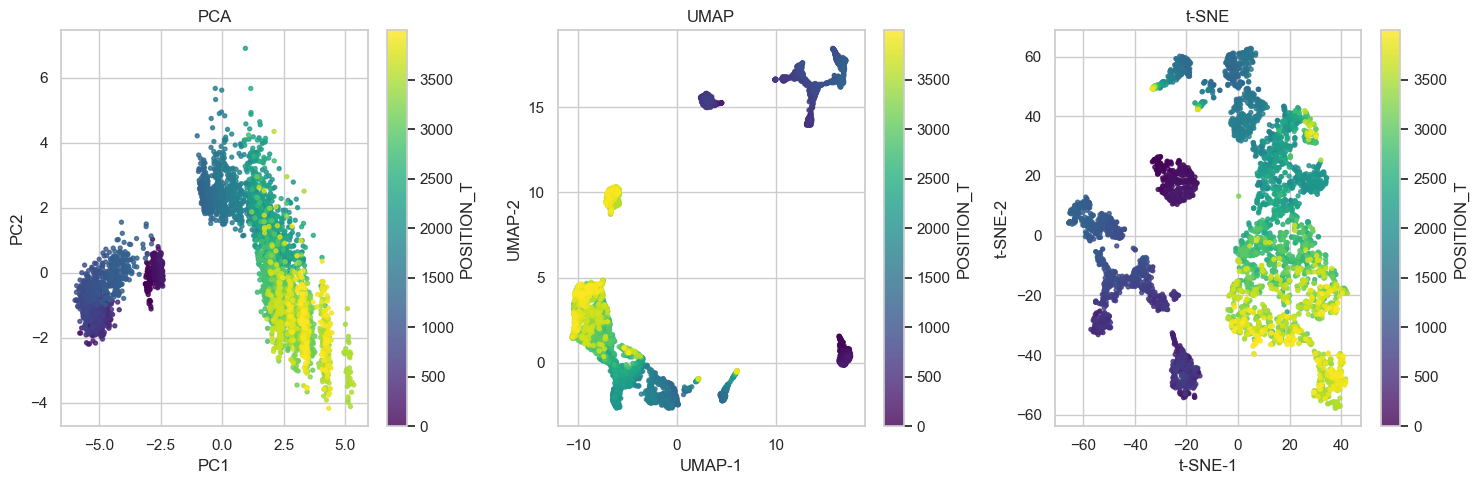

In [10]:
n_panels = 1 + int(has_umap) + int(has_tsne)
fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 5))
if n_panels == 1:
    axes = [axes]

t = field_features["POSITION_T"].to_numpy()
panel = 0

sc0 = axes[panel].scatter(Z_pca[:, 0], Z_pca[:, 1], c=t, cmap="viridis", s=8, alpha=0.8)
axes[panel].set_xlabel("PC1")
axes[panel].set_ylabel("PC2")
axes[panel].set_title("PCA")
plt.colorbar(sc0, ax=axes[panel], label="POSITION_T")
panel += 1

if has_umap:
    sc1 = axes[panel].scatter(Z_umap[:, 0], Z_umap[:, 1], c=t, cmap="viridis", s=8, alpha=0.8)
    axes[panel].set_xlabel("UMAP-1")
    axes[panel].set_ylabel("UMAP-2")
    axes[panel].set_title("UMAP")
    plt.colorbar(sc1, ax=axes[panel], label="POSITION_T")
    panel += 1

if has_tsne:
    sc2 = axes[panel].scatter(Z_tsne[:, 0], Z_tsne[:, 1], c=t, cmap="viridis", s=8, alpha=0.8)
    axes[panel].set_xlabel("t-SNE-1")
    axes[panel].set_ylabel("t-SNE-2")
    axes[panel].set_title("t-SNE")
    plt.colorbar(sc2, ax=axes[panel], label="POSITION_T")

plt.tight_layout()
plt.show()


### Reading t-SNE for time-series field data

- **Good for:** finding local clusters / regimes (e.g. early dense phase vs late reorganized phase).
- **Weak for:** global ordering and drawing a "time path" — distances between far-apart clusters are not meaningful.
- **Best practice here:** color by `POSITION_T` (as above). If you see smooth color gradients within clusters but sharp boundaries between clusters, that suggests phase-like transitions.
- **Do not** interpret t-SNE axis values or cluster separation magnitudes as physical units.

For temporal ordering, prefer **PCA trajectory** (next cell) or **PC1 vs time**.


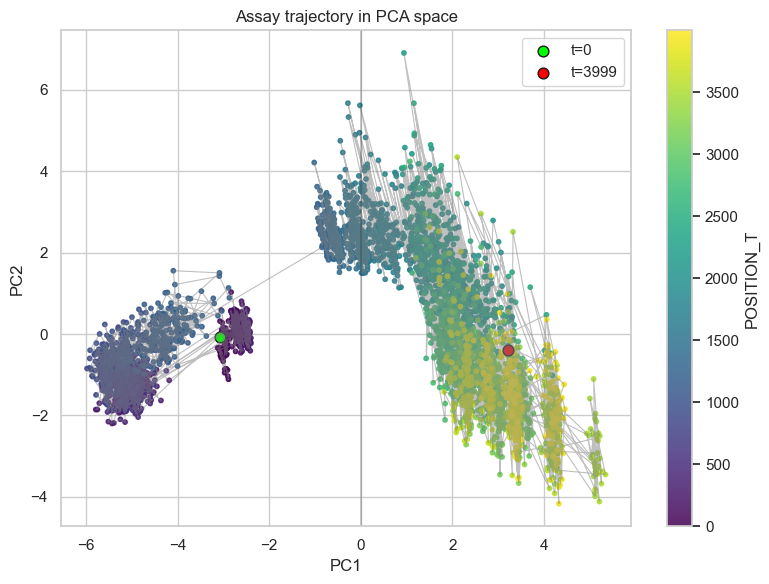

In [11]:
# PCA trajectory over time (path in latent space)
order = np.argsort(t)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(Z_pca[order, 0], Z_pca[order, 1], color="gray", lw=0.8, alpha=0.5)
sc = ax.scatter(Z_pca[:, 0], Z_pca[:, 1], c=t, cmap="viridis", s=10, alpha=0.85)
ax.axvline(0, color="k", lw=0.3)
ax.scatter(Z_pca[order[0], 0], Z_pca[order[0], 1], c="lime", s=60, edgecolor="k", label="t=0")
ax.scatter(Z_pca[order[-1], 0], Z_pca[order[-1], 1], c="red", s=60, edgecolor="k", label=f"t={int(t.max())}")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Assay trajectory in PCA space")
plt.colorbar(sc, label="POSITION_T")
ax.legend()
plt.tight_layout()
plt.show()


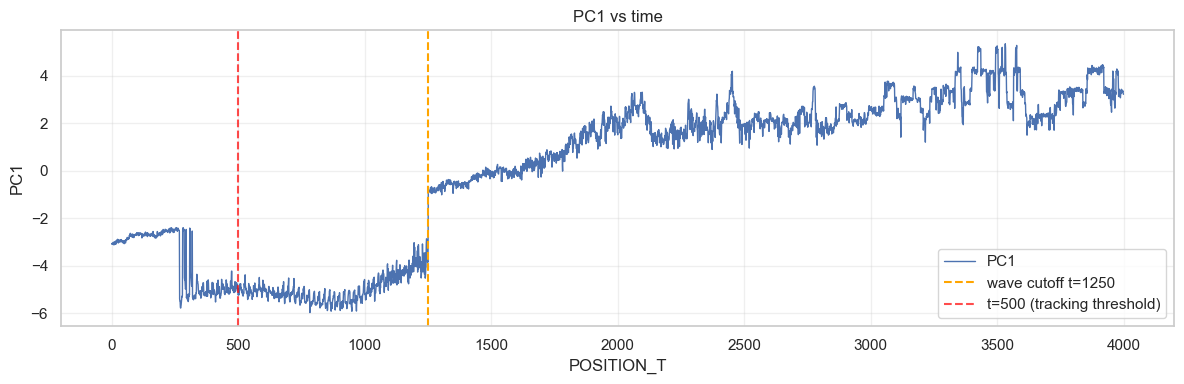

In [12]:
# Mark wave-cutoff and t=500 on timeline of PC1
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t, Z_pca[:, 0], lw=1.0, label="PC1")
ax.axvline(WAVE_CUTOFF_T, color="orange", ls="--", label=f"wave cutoff t={WAVE_CUTOFF_T}")
ax.axvline(500, color="red", ls="--", alpha=0.7, label="t=500 (tracking threshold)")
ax.set_xlabel("POSITION_T")
ax.set_ylabel("PC1")
ax.set_title("PC1 vs time")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:
# PCA loadings: what drives each axis?
loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
)
loadings["abs_PC1"] = loadings["PC1"].abs()
print("Top PC1 contributors:")
display(loadings.sort_values("abs_PC1", ascending=False).head(12)[["PC1", "PC2", "PC3"]])


Top PC1 contributors:


,PC1,PC2,PC3
mean_area,0.285857,-0.135825,0.127182
mean_quality,0.285854,-0.135858,0.127188
mean_perimeter,0.284342,0.064008,0.188749
mean_track_quality,0.282122,-0.170133,0.134157
n_active_tracks,-0.281040,-0.086721,-0.182967
n_spots,-0.279800,-0.084817,-0.193895
n_edges,-0.279514,-0.086024,-0.195091
mean_nn_dist,0.271694,-0.203852,0.157410
wave_perimeter_max,-0.260408,-0.163388,0.322855
wave_area_max,-0.258201,-0.172630,0.297497


## Optional: reduce temporal autocorrelation

Re-run embedding on **first differences** (change from previous time) to emphasize transitions instead of slow drift.


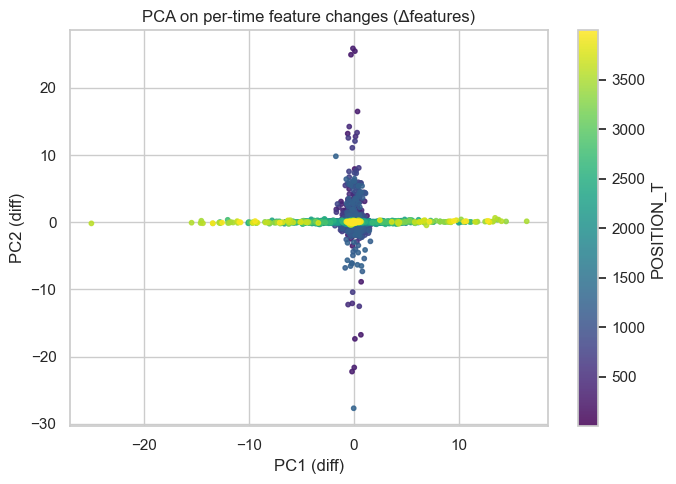

In [14]:
X_diff = X.diff().iloc[1:].fillna(0)
X_diff_scaled = StandardScaler().fit_transform(X_diff)
Z_pca_diff = PCA(n_components=2, random_state=0).fit_transform(X_diff_scaled)
t_diff = field_features["POSITION_T"].iloc[1:].to_numpy()

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(Z_pca_diff[:, 0], Z_pca_diff[:, 1], c=t_diff, cmap="viridis", s=10, alpha=0.85)
ax.set_xlabel("PC1 (diff)")
ax.set_ylabel("PC2 (diff)")
ax.set_title("PCA on per-time feature changes (Δfeatures)")
plt.colorbar(sc, label="POSITION_T")
plt.tight_layout()
plt.show()
